# 초기 100사이클 기반 배터리 수명 예측

초기 100사이클에서 추출한 피처로 총 수명인 `cycle_life_model`을
예측하는 회귀 모델을 구성한다.

## 1. 가공 데이터 불러오기

02_feature_engineering에서 저장한 파일의 해시와 데이터 구조를 확인한다.
입력 후보는 메타데이터에 기록된 13개 피처로 제한한다.

- Batch 1: 학습 및 내부 교차검증·hold-out 검증
- Batch 2: 모델과 설정을 고정한 후 최종 평가

Batch 1의 충전 프로토콜별 셀 수를 확인하여 내부 분할 방식을 결정할
근거를 마련한다. 동일 프로토콜의 셀을 함께 묶을지는 검증 목적에 맞춰 선택한다.

DAY1의 상관 분석은 보정 전 Batch 1의 46셀을 대상으로 수행했다.
DAY2에서는 후속 실험의 최종 수명을 5셀에 반영하고 미완료 5셀을 제외하여,
Batch 1의 모델링 대상은 41셀이다. 따라서 DAY1의 상관계수를
보정된 41셀의 상관계수로 해석하지 않는다.
EDA는 후보 설계의 출발점으로 사용하고, 최종 피처·모델은 DAY2의 내부 검증으로 선택한다.

DAY1에서 예시로 제안했던 그룹 3-fold CV는 DAY2 분할 단계에서
외부 5-fold로 구체화했으며, 기준 모델과 후보 모델에 동일한 분할을 유지했다.
규제 모델의 하이퍼파라미터는 각 외부 학습 폴드 안의 그룹 3-fold에서 선택한다.

In [21]:
from pathlib import Path
from hashlib import sha256
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display
import sklearn
from sklearn.model_selection import GroupShuffleSplit, GroupKFold
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.compose import TransformedTargetRegressor
from sklearn.metrics import mean_absolute_percentage_error, mean_squared_error
from time import perf_counter

from sklearn.linear_model import Ridge, ElasticNet
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

import matplotlib
import matplotlib.pyplot as plt
from time import perf_counter
import joblib

# 1. 사용할 데이터 버전을 고정
PROJECT_DIR = Path.cwd().resolve()
if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent
SNAPSHOT_DIR = (
    PROJECT_DIR / "data" / "processed"
    / "features_20261002_125401_694125"
)

metadata = json.loads(
    (SNAPSHOT_DIR / "metadata.json").read_text(encoding="utf-8")
)

feature_cols = list(metadata["feature_cols"])
target_col = metadata["target_col"]

# 식별정보와 타깃이 입력 후보에 포함되지 않았는지 확인
metadata_cols = ["batch", "cell_id", "barcode", "protocol", "protocol_note"]

assert metadata["observation_horizon"] == 100
assert target_col == "cycle_life_model"
assert len(feature_cols) == len(set(feature_cols)) == 13
assert not set(feature_cols).intersection(
    metadata_cols + ["cycle_life", target_col]
)

# 2. 저장 당시와 동일한 CSV인지 확인
csv_path = SNAPSHOT_DIR / "model_candidates.csv"
file_info = metadata["output_files"]["model_candidates.csv"]

if sha256(csv_path.read_bytes()).hexdigest() != file_info["sha256"]:
    raise ValueError("CSV가 저장 당시의 파일과 다릅니다. 변경 여부를 확인하세요.")

df_model = pd.read_csv(
    csv_path,
    dtype={
        "batch": "string",
        "barcode": "string",
        "protocol": "string",
        "protocol_note": "string",
    },
    keep_default_na=False,
)

assert len(df_model) == file_info["rows"]
assert df_model.columns.tolist() == file_info["columns"]
assert set(df_model["batch"]) == {"Batch 1", "Batch 2"}

# 3. 셀 식별키와 수치 유효성 확인
keys = ["batch", "cell_id"]

assert not df_model[keys].isna().any().any()
assert not df_model[keys].astype(str).apply(
    lambda col: col.str.strip().eq("")
).any().any()
assert not df_model.duplicated(keys).any()

numeric_cols = feature_cols + [target_col]
df_model[numeric_cols] = df_model[numeric_cols].apply(
    pd.to_numeric, errors="raise"
)

assert np.isfinite(df_model[numeric_cols].to_numpy()).all()
assert df_model[target_col].gt(100).all()
assert (
    df_model.groupby("batch").size().to_dict()
    == metadata["model_cells_by_batch"]
)

# 4. 배치별 역할 구분
# df_dev 전체가 학습 세트는 아니다. 다음 단계에서 내부 분할한다.
df_dev = df_model.loc[
    df_model["batch"].eq("Batch 1")
].copy().reset_index(drop=True)

df_test = df_model.loc[
    df_model["batch"].eq("Batch 2")
].copy().reset_index(drop=True)

print("저장 파일 해시·구조·수치 확인 완료")
print("입력 후보 수:", len(feature_cols))
print("타깃:", target_col)

display(pd.DataFrame({
    "batch": ["Batch 1", "Batch 2"],
    "role": ["학습·내부 검증", "최종 test"],
    "n_cells": [len(df_dev), len(df_test)],
}))

# 5. 내부 분할 검토를 위한 Batch 1 프로토콜별 셀 수
protocol_counts = (
    df_dev["protocol"]
    .value_counts(dropna=False)
    .rename_axis("protocol")
    .reset_index(name="n_cells")
)

print("Batch 1의 충전 프로토콜 수:", len(protocol_counts))
display(protocol_counts)

저장 파일 해시·구조·수치 확인 완료
입력 후보 수: 13
타깃: cycle_life_model


,batch,role,n_cells
0,Batch 1,학습·내부 검증,41
1,Batch 2,최종 test,39


Batch 1의 충전 프로토콜 수: 22


,protocol,n_cells
0,3.6C(80%)-3.6C,3
1,4C(80%)-4C,2
2,4.8C(80%)-4.8C,2
3,5.4C(60%)-3C,2
4,5.4C(60%)-3.6C,2
5,5.4C(70%)-3C,2
6,5.4C(80%)-5.4C,2
7,6C(40%)-3C,2
8,6C(40%)-3.6C,2
9,6C(50%)-3C,2


## 2. 프로토콜 단위 hold-out 및 교차검증 구성

학습에 포함되지 않은 충전 조건에서도 수명을 예측할 수 있는지 확인하기 위해,
동일한 충전 프로토콜의 셀을 하나의 그룹으로 취급한다.

Batch 1 프로토콜의 20%를 hold-out 검증용으로 분리하고,
나머지 학습 부분에서 5-fold GroupKFold를 구성한다.
Hold-out 분할의 random_state는 42로 고정한다.

피처 조합과 모델 설정은 학습 부분의 CV로 비교한다.
스케일링과 데이터 기반 피처 선택도 각 CV 학습 폴드 안에서 수행한다.
Hold-out은 선택한 설정을 검증하는 데 사용하고,
Batch 2는 최종 평가용으로 유지한다.

이 검증은 미관측 충전 프로토콜에 대한 일반화를 평가한다.
시간 순서에 따른 일반화와 배치 변화의 영향을 모두 검증하는 것은 아니다.

In [11]:
# 1. 분할 설정
SEED = 42
HOLDOUT_GROUP_RATIO = 0.20
N_SPLITS = 5
GROUP_COL = "protocol"

assert df_dev[GROUP_COL].notna().all()
assert df_dev[GROUP_COL].str.strip().ne("").all()
assert df_model["barcode"].notna().all()
assert df_model["barcode"].str.strip().ne("").all()
assert not df_model["barcode"].duplicated().any()

# 2. Batch 1의 프로토콜 단위 hold-out
holdout_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=HOLDOUT_GROUP_RATIO,
    random_state=SEED,
)

train_idx, valid_idx = next(
    holdout_splitter.split(
        df_dev[feature_cols],
        groups=df_dev[GROUP_COL],
    )
)

df_train = df_dev.iloc[train_idx].copy().reset_index(drop=True)
df_valid = df_dev.iloc[valid_idx].copy().reset_index(drop=True)

train_protocols = set(df_train[GROUP_COL])
valid_protocols = set(df_valid[GROUP_COL])

assert train_protocols.isdisjoint(valid_protocols)
assert len(df_train) + len(df_valid) == len(df_dev)
assert len(train_protocols) >= N_SPLITS

# 3. 학습 부분에서만 그룹 CV 구성
# 기본 shuffle=False이므로 GroupKFold에는 난수가 사용되지 않는다.
group_cv = GroupKFold(n_splits=N_SPLITS)

# 이후 모델 비교에서도 df_train의 행 순서와 이 인덱스를 유지한다.
cv_splits = list(
    group_cv.split(
        df_train[feature_cols],
        groups=df_train[GROUP_COL],
    )
)

cv_val_fold = np.full(len(df_train), -1, dtype=int)
cv_records = []

for fold, (fit_idx, eval_idx) in enumerate(cv_splits, start=1):
    fit_part = df_train.iloc[fit_idx]
    eval_part = df_train.iloc[eval_idx]

    overlap = set(fit_part[GROUP_COL]) & set(eval_part[GROUP_COL])
    assert len(overlap) == 0

    # 각 셀이 CV 검증용으로 사용되는 폴드 번호
    cv_val_fold[eval_idx] = fold

    cv_records.append({
        "fold": fold,
        "train_cells": len(fit_part),
        "validation_cells": len(eval_part),
        "train_protocols": fit_part[GROUP_COL].nunique(),
        "validation_protocols": eval_part[GROUP_COL].nunique(),
        "shared_protocols": len(overlap),
    })

assert (cv_val_fold > 0).all()
df_cv_summary = pd.DataFrame(cv_records)

# 4. 셀별 분할·폴드 배정표
id_cols = ["batch", "cell_id", "barcode", "protocol"]

split_manifest = pd.concat([
    df_train[id_cols].assign(split="train", cv_val_fold=cv_val_fold),
    df_valid[id_cols].assign(split="valid", cv_val_fold=pd.NA),
    df_test[id_cols].assign(split="test", cv_val_fold=pd.NA),
], ignore_index=True)

split_manifest["cv_val_fold"] = (
    split_manifest["cv_val_fold"].astype("Int64")
)

assert len(split_manifest) == len(df_model)
assert not split_manifest.duplicated(["batch", "cell_id"]).any()

# 5. 분할 결과와 설정 저장
created_at = pd.Timestamp.now(tz="Asia/Seoul")
RUN_DIR = (
    SNAPSHOT_DIR.parents[2] / "outputs" / "modeling"
    / f"group_split_{created_at.strftime('%Y%m%d_%H%M%S_%f')}"
)
RUN_DIR.mkdir(parents=True, exist_ok=False)

manifest_path = RUN_DIR / "split_manifest.csv"
split_manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")

split_config = {
    "created_at": created_at.isoformat(),
    "input_snapshot": str(SNAPSHOT_DIR),
    "input_csv_sha256": metadata["output_files"]["model_candidates.csv"]["sha256"],
    "group_column": GROUP_COL,
    "holdout_method": "GroupShuffleSplit",
    "holdout_group_ratio": HOLDOUT_GROUP_RATIO,
    "holdout_random_state": SEED,
    "cv_method": "GroupKFold",
    "cv_n_splits": N_SPLITS,
    "cv_shuffle": False,
    "cv_val_fold_definition": "각 셀이 CV 검증용으로 사용되는 폴드 번호",
    "feature_candidates": feature_cols,
    "target": target_col,
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "split_manifest_sha256": sha256(manifest_path.read_bytes()).hexdigest(),
}

(RUN_DIR / "split_config.json").write_text(
    json.dumps(split_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 6. 결과 확인
print("배치별 분할 결과")
display(
    split_manifest.groupby(["batch", "split"], sort=False).agg(
        n_cells=("cell_id", "size"),
        n_protocols=("protocol", "nunique"),
    )
)

print("학습 부분의 그룹 CV 구성")
display(df_cv_summary)

print("Batch 1 학습·hold-out 사이 공통 프로토콜 수:",
      len(train_protocols & valid_protocols))
print("분할 기록 저장 위치:", RUN_DIR)

배치별 분할 결과


n_cells  n_protocols
batch   split                      
Batch 1 train       31           17
        valid       10            5
Batch 2 test        39           12

학습 부분의 그룹 CV 구성


,fold,train_cells,validation_cells,train_protocols,validation_protocols,shared_protocols
0,1,24,7,13,4,0
1,2,25,6,14,3,0
2,3,25,6,14,3,0
3,4,25,6,14,3,0
4,5,25,6,13,4,0


Batch 1 학습·hold-out 사이 공통 프로토콜 수: 0
분할 기록 저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254


## 3. 기준 모델의 그룹 교차검증

EDA에서 주요 후보로 확인한 `delta_q_log_var` 하나를 사용하여
선형 회귀의 예측력을 확인한다.
비교 기준으로 각 CV 학습 부분의 수명 중앙값을 예측하는 모델을 추가한다.

선형 회귀는 원래 수명을 학습하는 방식과 log10 수명을 학습하는 방식을 비교한다.
입력 피처의 로그 분산과 타깃의 로그 변환은 서로 다른 처리다.

모든 모델은 앞서 고정한 동일한 5-fold 그룹 CV를 사용한다.
주 지표는 MAPE(%), 보조 지표는 RMSE(사이클)이며,
로그 모델도 예측을 원래 사이클 단위로 되돌린 후 평가한다.

폴드별 지표의 평균과 표준편차를 함께 확인한다.
표준편차는 폴드 간 변동을 나타내며 신뢰구간을 의미하지 않는다.
최종 모델과 피처 조합은 후속 후보 비교를 거쳐 결정한다.

In [13]:
# 1. 이번 비교에서 사용할 단일 피처
baseline_features = ["delta_q_log_var"]
assert set(baseline_features).issubset(feature_cols)

X_baseline = df_train[baseline_features].copy()
y_baseline = df_train[target_col].copy()

assert np.isfinite(X_baseline.to_numpy()).all()
assert np.isfinite(y_baseline.to_numpy()).all()
assert y_baseline.gt(0).all()

# 저장된 분할과 현재 학습 데이터의 행 순서 확인
saved_train = (
    split_manifest.loc[split_manifest["split"].eq("train")]
    .reset_index(drop=True)
)
pd.testing.assert_frame_equal(
    df_train[["batch", "cell_id"]].reset_index(drop=True),
    saved_train[["batch", "cell_id"]],
)
saved_cv_fold = saved_train["cv_val_fold"].to_numpy(dtype=int)


# 2. 로그 타깃의 역변환
def inverse_log10(values):
    return np.power(10.0, values)


baseline_models = {
    "Dummy_median": DummyRegressor(strategy="median"),
    "Linear_raw": LinearRegression(),
    "Linear_log10": TransformedTargetRegressor(
        regressor=LinearRegression(),
        func=np.log10,
        inverse_func=inverse_log10,
    ),
}

# 3. 기존 그룹 CV에서만 학습·평가
fold_records = []
prediction_tables = []

for model_name, estimator in baseline_models.items():
    prediction_count = np.zeros(len(df_train), dtype=int)

    for fold, (fit_idx, eval_idx) in enumerate(cv_splits, start=1):
        fit_groups = set(df_train.iloc[fit_idx]["protocol"])
        eval_groups = set(df_train.iloc[eval_idx]["protocol"])

        assert fit_groups.isdisjoint(eval_groups)
        assert np.all(saved_cv_fold[eval_idx] == fold)

        model = clone(estimator)
        model.fit(
            X_baseline.iloc[fit_idx],
            y_baseline.iloc[fit_idx],
        )

        y_true = y_baseline.iloc[eval_idx].to_numpy()
        # 로그 모델도 predict 결과는 이미 원래 사이클 단위다.
        y_pred = np.asarray(
            model.predict(X_baseline.iloc[eval_idx])
        ).ravel()

        if not np.isfinite(y_pred).all():
            raise ValueError(f"{model_name}, fold {fold}: 예측값 확인 필요")

        fold_records.append({
            "model": model_name,
            "fold": fold,
            "n_validation": len(eval_idx),
            "MAPE_pct": mean_absolute_percentage_error(y_true, y_pred) * 100,
            "RMSE_cycles": np.sqrt(mean_squared_error(y_true, y_pred)),
            "nonpositive_predictions": int((y_pred <= 0).sum()),
        })

        # 각 셀이 학습에서 제외된 상태로 받은 예측을 보존
        fold_predictions = df_train.iloc[eval_idx][
            ["batch", "cell_id", "protocol"]
        ].copy()
        fold_predictions["model"] = model_name
        fold_predictions["fold"] = fold
        fold_predictions["y_true"] = y_true
        fold_predictions["y_pred"] = y_pred
        fold_predictions["APE_pct"] = (
            np.abs(y_true - y_pred) / y_true * 100
        )
        prediction_tables.append(fold_predictions)
        prediction_count[eval_idx] += 1

    assert np.all(prediction_count == 1)

df_baseline_cv = pd.DataFrame(fold_records)
df_baseline_oof = pd.concat(prediction_tables, ignore_index=True)

# 4. 폴드별 지표의 단순평균과 표본표준편차
df_baseline_summary = (
    df_baseline_cv.groupby("model", sort=False)
    .agg(
        n_folds=("fold", "size"),
        MAPE_mean_pct=("MAPE_pct", "mean"),
        MAPE_std_pp=("MAPE_pct", "std"),
        RMSE_mean_cycles=("RMSE_cycles", "mean"),
        RMSE_std_cycles=("RMSE_cycles", "std"),
        nonpositive_predictions=("nonpositive_predictions", "sum"),
    )
    .reset_index()
    .sort_values("MAPE_mean_pct")
)

# 5. 지표·셀별 예측·실험 설정 저장
saved_at = pd.Timestamp.now(tz="Asia/Seoul")
BASELINE_DIR = RUN_DIR / f"baseline_{saved_at.strftime('%Y%m%d_%H%M%S_%f')}"
BASELINE_DIR.mkdir(parents=True, exist_ok=False)

result_tables = {
    "baseline_cv_metrics.csv": df_baseline_cv,
    "baseline_cv_summary.csv": df_baseline_summary,
    "baseline_oof_predictions.csv": df_baseline_oof,
}

for filename, table in result_tables.items():
    table.to_csv(BASELINE_DIR / filename, index=False, encoding="utf-8-sig")

baseline_config = {
    "saved_at": saved_at.isoformat(),
    "split_directory": str(RUN_DIR),
    "split_manifest_sha256": sha256(
        (RUN_DIR / "split_manifest.csv").read_bytes()
    ).hexdigest(),
    "input_snapshot": str(SNAPSHOT_DIR),
    "features": baseline_features,
    "target": target_col,
    "n_training_cells": len(df_train),
    "n_cv_folds": len(cv_splits),
    "models": {
        "Dummy_median": "각 CV 학습 부분의 원래 수명 중앙값",
        "Linear_raw": "단일 피처 선형 회귀, 원래 수명 학습",
        "Linear_log10": "단일 피처 선형 회귀, log10 수명 학습 후 10**예측 역변환",
    },
    "primary_metric": "폴드별 MAPE(%)의 단순평균",
    "secondary_metric": "폴드별 RMSE(사이클)의 단순평균",
    "std_definition": "폴드별 지표의 표본표준편차, ddof=1",
    "holdout_evaluated": False,
    "batch2_evaluated": False,
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
}

(BASELINE_DIR / "baseline_config.json").write_text(
    json.dumps(baseline_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("기준 모델 그룹 CV 비교")
display(df_baseline_summary.round(3))

print("폴드별 성능")
display(df_baseline_cv.round(3))

print("저장 위치:", BASELINE_DIR)

기준 모델 그룹 CV 비교


,model,n_folds,MAPE_mean_pct,MAPE_std_pp,RMSE_mean_cycles,RMSE_std_cycles,nonpositive_predictions
2,Linear_log10,5,10.178,2.621,117.864,61.384,0
1,Linear_raw,5,13.756,5.449,145.764,82.803,0
0,Dummy_median,5,24.183,10.899,238.252,177.807,0


폴드별 성능


,model,fold,n_validation,MAPE_pct,RMSE_cycles,nonpositive_predictions
0,Dummy_median,1,7,22.756,176.443,0
1,Dummy_median,2,6,12.062,98.511,0
2,Dummy_median,3,6,35.010,543.076,0
3,Dummy_median,4,6,15.413,137.305,0
4,Dummy_median,5,6,35.676,235.926,0
5,Linear_raw,1,7,15.805,130.882,0
6,Linear_raw,2,6,8.170,86.091,0
7,Linear_raw,3,6,16.479,281.653,0
8,Linear_raw,4,6,8.014,74.500,0
9,Linear_raw,5,6,20.314,155.695,0


저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254/baseline_20261002_133638_600324


### 기준 모델 비교 결과와 해석

5개 그룹 CV 폴드의 평균 MAPE는 중앙값 기준 모델 24.183%,
원래 수명을 학습한 선형 회귀 13.756%,
로그 수명을 학습한 선형 회귀 10.178%로 나타났다.

ΔQ 로그 분산 하나를 사용한 모델이 중앙값 기준보다 낮은 오차를 보여,
초기 방전 곡선의 변화가 수명 예측에 유용한 정보를 포함한다는
EDA의 가설을 이번 내부 검증에서 뒷받침하였다.

로그 수명 회귀는 원래 수명 회귀보다 평균 MAPE가 3.578%p 낮았고,
폴드별 RMSE의 평균도 145.764사이클에서 117.864사이클로 감소하였다.
MAPE의 폴드 간 표준편차 역시 5.449%p에서 2.621%p로 줄었다.
다만 5개 폴드 중 4개에서 개선됐으며, 4번 폴드에서는
원래 수명을 학습한 모델의 오차가 더 작았다.

로그 모델에서도 3번 폴드의 MAPE는 14.312%,
RMSE는 224.645사이클로 상대적으로 컸다.
따라서 평균 성능뿐 아니라 어떤 셀과 충전 조건에서 오차가 커지는지도
후속 잔차 분석으로 확인할 필요가 있다.

현재 결과는 Batch 1 학습 부분의 내부 CV 성능이다.
Hold-out과 Batch 2의 평가 결과는 아직 없으므로 최종 성능으로 해석하지 않는다.

단일 피처만으로도 예측력이 확인된 만큼, 이후 피처를 추가할 때는
모델 복잡도가 증가하는 만큼 실제 검증 오차가 개선되는지 확인한다.

### 보조 피처 추가 및 규제 회귀 모델 비교

단일 피처 기준 모델에서는 ΔQ 로그분산으로 log10(Cycle Life)를 예측한
선형회귀의 그룹 CV 성능이 가장 좋았다.
이번에는 로그 타깃을 공통으로 사용하여 보조 피처와 규제의 효과를 비교한다.

피처 조합은 다음과 같이 구성한다.

- dq_only: ΔQ 로그분산 1개
- measurement: ΔQ 로그분산에 용량 변화, 평균 온도 중앙값,
  충전 시간 중앙값, 내부저항 중앙값을 추가한 5개
- plus_charge: measurement에 1단계 C-rate, 2단계 C-rate,
  전환 SOC를 추가한 8개

EDA에서 정보 중복이 컸던 ΔQ 평균·최솟값, 최대 온도,
초기 용량 감소율은 이번 조합에 중복해서 포함하지 않는다.

Ridge는 계수를 축소하여 복잡도를 조절하고,
Elastic Net은 계수 축소와 일부 계수를 0으로 만드는 효과를 함께 검토한다.
추가 피처가 성능을 개선하는지는 실행 결과로 판단한다.

평가는 기존 5-fold 그룹 CV를 유지한다.
각 평가 폴드의 학습 데이터 안에서 별도의 3-fold 그룹 CV를 수행해
규제 강도와 Elastic Net의 l1_ratio를 선택한다.
표준화도 이 내부 CV의 학습 부분에만 fit한다.

모든 오차는 예측값을 원래 사이클 단위로 되돌린 후 계산한다.
MAPE 평균을 중심으로 RMSE와 폴드별 변동을 함께 비교한다.
피처 조합과 모델을 이 결과로 비교하므로, 최종 성능 판단을 위한
Batch 1 hold-out과 Batch 2 test는 별도로 유지한다.

In [15]:
# 피처 조합: 최종 선택이 아닌 비교 후보
measurement_features = [
    "delta_q_log_var",
    "qd_change_100_10",
    "tavg_median",
    "chargetime_median",
    "ir_median",
]

feature_sets = {
    "dq_only": ["delta_q_log_var"],
    "measurement": measurement_features,
    "plus_charge": measurement_features + [
        "charge_c1",
        "charge_c2",
        "switch_soc",
    ],
}

# 결정적인 계산 방식을 사용한다.
model_specs = {
    "Ridge_log10": Ridge(solver="svd"),
    "ElasticNet_log10": ElasticNet(
        max_iter=100_000,
        tol=1e-6,
        selection="cyclic",
    ),
}

# 작은 데이터이므로 탐색 범위를 제한한다.
param_grids = {
    "Ridge_log10": {
        "regressor__model__alpha": [0.01, 0.1, 1.0, 10.0, 100.0],
    },
    "ElasticNet_log10": {
        "regressor__model__alpha": [0.0001, 0.001, 0.01, 0.1],
        "regressor__model__l1_ratio": [0.1, 0.5, 0.9],
    },
}

def make_log_pipeline(model):
    return TransformedTargetRegressor(
        regressor=Pipeline([
            ("scale", StandardScaler()),
            ("model", clone(model)),
        ]),
        func=np.log10,
        inverse_func=inverse_log10,
    )

display(pd.DataFrame([
    {
        "feature_set": name,
        "n_features": len(cols),
        "features": ", ".join(cols),
    }
    for name, cols in feature_sets.items()
]))

,feature_set,n_features,features
0,dq_only,1,delta_q_log_var
1,measurement,5,"delta_q_log_var, qd_change_100_10, tavg_median..."
2,plus_charge,8,"delta_q_log_var, qd_change_100_10, tavg_median..."


In [17]:
# 기존 분할과 학습 행 순서가 유지됐는지 확인
keys = ["batch", "cell_id"]
train_manifest = (
    split_manifest.loc[split_manifest["split"].eq("train")]
    .reset_index(drop=True)
)

pd.testing.assert_frame_equal(
    df_train[keys].reset_index(drop=True),
    train_manifest[keys],
)

assert len(df_train) == 31
assert df_train["batch"].eq("Batch 1").all()
assert np.isfinite(df_train[feature_cols].to_numpy(dtype=float)).all()
assert df_train[target_col].gt(0).all()

# 실행 설정을 먼저 저장
started_at = pd.Timestamp.now(tz="Asia/Seoul")
started_timer = perf_counter()

CANDIDATE_DIR = (
    RUN_DIR / f"candidates_{started_at.strftime('%Y%m%d_%H%M%S_%f')}"
)
CANDIDATE_DIR.mkdir(parents=True, exist_ok=False)

candidate_config = {
    "status": "running",
    "started_at": started_at.isoformat(),
    "snapshot_dir": str(SNAPSHOT_DIR),
    "split_dir": str(RUN_DIR),
    "split_manifest_sha256": sha256(
        (RUN_DIR / "split_manifest.csv").read_bytes()
    ).hexdigest(),
    "feature_sets": feature_sets,
    "target": target_col,
    "target_transform": "log10; predictions returned in cycles",
    "estimators": {
        name: str(model) for name, model in model_specs.items()
    },
    "param_grids": param_grids,
    "outer_folds": len(cv_splits),
    "inner_folds": 3,
    "group_column": "protocol",
    "group_cv_shuffle": False,
    "original_split_seed": int(SEED),
    "selection_scoring": "neg_mean_absolute_percentage_error",
    "aggregation": "unweighted fold mean; sample std (ddof=1)",
    "holdout_evaluated": False,
    "batch2_test_evaluated": False,
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
}

config_path = CANDIDATE_DIR / "candidate_config.json"
config_path.write_text(
    json.dumps(candidate_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

metric_records = []
oof_parts = []
inner_manifest_parts = []

for fold, (fit_idx, eval_idx) in enumerate(cv_splits, start=1):
    fit_df = df_train.iloc[fit_idx]
    eval_df = df_train.iloc[eval_idx]

    # 기존 기준 모델과 동일한 평가 폴드인지 확인
    expected_eval_idx = np.flatnonzero(
        train_manifest["cv_val_fold"].to_numpy(dtype=int) == fold
    )
    np.testing.assert_array_equal(
        np.sort(eval_idx), expected_eval_idx
    )

    assert set(fit_df["protocol"]).isdisjoint(eval_df["protocol"])

    # 안쪽 CV는 바깥 학습 데이터만 사용
    inner_splits = list(
        GroupKFold(n_splits=3).split(
            fit_df,
            groups=fit_df["protocol"],
        )
    )

    # 안쪽 폴드 배정도 저장
    for inner_fold, (inner_fit, inner_eval) in enumerate(
        inner_splits, start=1
    ):
        assert set(
            fit_df.iloc[inner_fit]["protocol"]
        ).isdisjoint(
            fit_df.iloc[inner_eval]["protocol"]
        )

        inner_part = fit_df.iloc[inner_eval][
            ["batch", "cell_id", "protocol"]
        ].copy()
        inner_part["outer_fold"] = fold
        inner_part["inner_validation_fold"] = inner_fold
        inner_manifest_parts.append(inner_part)

    y_fit = fit_df[target_col]
    y_true = eval_df[target_col].to_numpy(dtype=float)

    for set_name, cols in feature_sets.items():
        for model_name, model in model_specs.items():
            search = GridSearchCV(
                estimator=make_log_pipeline(model),
                param_grid=param_grids[model_name],
                scoring="neg_mean_absolute_percentage_error",
                cv=inner_splits,
                refit=True,
                n_jobs=1,
                error_score="raise",
            )

            # 원래 사이클 단위의 타깃을 전달한다.
            search.fit(fit_df[cols], y_fit)

            # TTR이 원래 사이클 단위로 되돌린 예측값
            y_pred = search.predict(eval_df[cols])
            assert np.isfinite(y_pred).all()

            metric_records.append({
                "feature_set": set_name,
                "model": model_name,
                "n_features": len(cols),
                "fold": fold,
                "n_validation": len(eval_df),
                "MAPE_pct": (
                    mean_absolute_percentage_error(y_true, y_pred) * 100
                ),
                "RMSE_cycles": np.sqrt(
                    mean_squared_error(y_true, y_pred)
                ),
                "nonpositive_predictions": int((y_pred <= 0).sum()),
                "inner_best_MAPE_pct": -search.best_score_ * 100,
                "best_params": json.dumps(
                    search.best_params_, sort_keys=True
                ),
            })

            part = eval_df[
                ["batch", "cell_id", "protocol"]
            ].copy()
            part["feature_set"] = set_name
            part["model"] = model_name
            part["fold"] = fold
            part["y_true"] = y_true
            part["y_pred"] = y_pred
            part["APE_pct"] = (
                np.abs(y_true - y_pred) / y_true * 100
            )
            oof_parts.append(part)

    print(f"바깥 CV {fold}/{len(cv_splits)} 완료")

df_candidate_cv = pd.DataFrame(metric_records)
df_candidate_oof = pd.concat(oof_parts, ignore_index=True)
df_inner_manifest = pd.concat(inner_manifest_parts, ignore_index=True)

# 각 후보에서 모든 학습 셀이 정확히 한 번 평가됐는지 확인
assert len(df_candidate_cv) == 30
assert len(df_candidate_oof) == 6 * len(df_train)
assert (
    df_candidate_oof.groupby(
        ["feature_set", "model", "batch", "cell_id"]
    ).size().eq(1).all()
)

df_candidate_summary = (
    df_candidate_cv
    .groupby(["feature_set", "model", "n_features"], as_index=False)
    .agg(
        n_folds=("fold", "nunique"),
        MAPE_mean_pct=("MAPE_pct", "mean"),
        MAPE_std_pp=("MAPE_pct", "std"),
        RMSE_mean_cycles=("RMSE_cycles", "mean"),
        RMSE_std_cycles=("RMSE_cycles", "std"),
        nonpositive_predictions=("nonpositive_predictions", "sum"),
    )
)

# 기존 기준 모델 결과를 재학습 없이 함께 비교
baseline_comparison = df_baseline_summary.copy()
is_dummy = baseline_comparison["model"].eq("Dummy_median")
baseline_comparison["feature_set"] = np.where(
    is_dummy, "none", "dq_only"
)
baseline_comparison["n_features"] = np.where(is_dummy, 0, 1)

df_model_comparison = pd.concat(
    [baseline_comparison, df_candidate_summary],
    ignore_index=True,
)

baseline_mape = float(
    df_baseline_summary.loc[
        df_baseline_summary["model"].eq("Linear_log10"),
        "MAPE_mean_pct",
    ].iloc[0]
)

# 양수이면 기존 단일 피처 로그 선형회귀보다 개선
df_model_comparison["MAPE_gain_vs_linear_pp"] = (
    baseline_mape - df_model_comparison["MAPE_mean_pct"]
)
df_model_comparison = df_model_comparison.sort_values(
    "MAPE_mean_pct"
).reset_index(drop=True)

# 결과 저장
result_tables = {
    "candidate_cv_metrics.csv": df_candidate_cv,
    "candidate_cv_summary.csv": df_candidate_summary,
    "candidate_oof_predictions.csv": df_candidate_oof,
    "inner_cv_manifest.csv": df_inner_manifest,
    "model_comparison.csv": df_model_comparison,
}

for filename, table in result_tables.items():
    table.to_csv(
        CANDIDATE_DIR / filename, index=False, encoding="utf-8-sig"
    )

candidate_config.update({
    "status": "completed",
    "finished_at": pd.Timestamp.now(tz="Asia/Seoul").isoformat(),
    "elapsed_seconds": perf_counter() - started_timer,
    "output_sha256": {
        filename: sha256(
            (CANDIDATE_DIR / filename).read_bytes()
        ).hexdigest()
        for filename in result_tables
    },
})
config_path.write_text(
    json.dumps(candidate_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("\n기준 모델과 규제 모델의 그룹 CV 비교")
display(df_model_comparison[[
    "feature_set", "model", "n_features",
    "MAPE_mean_pct", "MAPE_std_pp",
    "RMSE_mean_cycles", "RMSE_std_cycles",
    "MAPE_gain_vs_linear_pp",
]].round(3))

print("저장 위치:", CANDIDATE_DIR)

바깥 CV 1/5 완료
바깥 CV 2/5 완료
바깥 CV 3/5 완료
바깥 CV 4/5 완료
바깥 CV 5/5 완료

기준 모델과 규제 모델의 그룹 CV 비교


,feature_set,model,n_features,MAPE_mean_pct,MAPE_std_pp,RMSE_mean_cycles,RMSE_std_cycles,MAPE_gain_vs_linear_pp
0,dq_only,Linear_log10,1,10.178,2.621,117.864,61.384,0.000
1,dq_only,Ridge_log10,1,10.198,2.946,119.917,67.626,-0.020
2,dq_only,ElasticNet_log10,1,10.431,3.197,123.433,74.115,-0.253
3,plus_charge,ElasticNet_log10,8,11.384,3.663,128.345,81.805,-1.207
4,measurement,ElasticNet_log10,5,12.547,4.296,132.301,81.848,-2.369
5,measurement,Ridge_log10,5,13.282,5.168,143.120,97.736,-3.104
6,plus_charge,Ridge_log10,8,13.469,5.472,149.062,99.847,-3.291
7,dq_only,Linear_raw,1,13.756,5.449,145.764,82.803,-3.579
8,none,Dummy_median,0,24.183,10.899,238.252,177.807,-14.005


저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254/candidates_20261002_134908_638429


### 피처 조합 및 규제 모델 비교 결과 해석

ΔQ 로그분산 단일 피처를 사용한 로그 타깃 선형회귀가
평균 MAPE 10.178%, 평균 RMSE 117.864사이클로
비교한 후보 중 가장 낮은 오차를 보였다.
MAPE의 폴드 표준편차도 2.621%p로 가장 작았다.

단일 피처 Ridge의 MAPE는 10.198%로 선형회귀와 거의 같았다.
차이가 0.020%p에 불과하므로 선형회귀의 통계적 우위를
단정하기보다는, 규제 추가에 따른 뚜렷한 개선이 없었다고 해석한다.

측정 피처 5개와 충전 조건을 포함한 피처 8개 모델은
단일 피처 선형회귀보다 오차와 폴드별 변동이 컸다.
다만 Elastic Net에서는 충전 조건을 추가하면서
MAPE가 12.547%에서 11.384%로 개선됐다.
따라서 충전 조건이 전혀 도움이 되지 않는다고 볼 수는 없지만,
이번 비교에서는 단일 피처 기준을 넘어서는 성능을 얻지 못했다.

이 결과는 EDA에서 수명과 상관관계가 관찰된 변수를 추가하더라도
이미 사용 중인 피처에 더해 예측에 도움이 되는 정보가
충분히 늘어나는 것은 아니라는 점을 보여준다.
적은 학습 표본과 피처 간 정보 중복이 가능한 설명이지만,
현재 결과만으로 성능 저하의 원인을 확정하지는 않는다.

현재 데이터와 검증 조건에서는 피처 수를 늘리기보다
ΔQ 로그분산 단일 피처 모델의 단순성과 예측 성능을
우선 고려할 근거가 있다.
다만 이 결과는 Batch 1 학습 31셀의 그룹 CV 결과이므로,
선택한 후보의 성능은 별도로 보존한 hold-out에서 확인해야 한다.

### 선택 후보의 Batch 1 hold-out 검증

그룹 CV 결과를 근거로 ΔQ 로그분산 단일 피처를 사용하는
로그 타깃 선형회귀를 hold-out 평가 후보로 선택한다.
이 모델은 비교한 후보 중 평균 MAPE와 RMSE가 가장 낮았으며,
성능이 비슷한 단일 피처 Ridge보다 설정이 단순하다.

기존 학습 31셀로 모델을 학습하고, 프로토콜이 겹치지 않도록
분리해 둔 hold-out 10셀에서 성능을 확인한다.
Batch 2는 최종 평가를 위해 유지한다.

주 지표는 MAPE(%), 보조 지표는 RMSE(사이클)이다.
CV와의 MAPE 차이는 다음과 같이 정의한다.

- MAPE 차이 = hold-out MAPE − CV 평균 MAPE
- 양수: hold-out에서 오차 증가
- 음수: hold-out에서 오차 감소

CV의 각 모델은 24~25셀로 학습하지만 이번 모델은 31셀로 학습한다.
평가 표본도 10셀로 작으므로 지표 차이만으로 과적합을 단정하지 않는다.

셀별 잔차는 예측 수명 − 실제 수명으로 계산한다.
양의 잔차는 수명을 실제보다 길게 예측한 경우이므로,
전체 평균 오차와 함께 수명 과대 예측 사례를 확인한다.

이 hold-out은 모델 학습과 이번 후보 비교에는 사용하지 않았지만,
DAY1에서는 전체 Batch 1을 대상으로 EDA를 수행했다는 한계가 있다.
평가 결과에 맞춰 모델을 반복 수정하면 독립 확인 자료로서의 역할이
줄어든다는 점도 고려한다.

선택 후보: Linear_log10


,evaluation,n_cells,MAPE_pct,RMSE_cycles
0,Batch 1 CV: 5-fold mean,31,10.178,117.864
1,Batch 1 hold-out,10,9.146,212.015


MAPE 차이 (hold-out − CV): -1.032%p

셀별 오차: APE가 큰 순서


,batch,cell_id,protocol,y_true,y_pred,error_cycles,APE_pct
2,Batch 1,2,3.6C(80%)-3.6C,2237.0,1631.156,-605.844,27.083
5,Batch 1,19,5.4C(70%)-3C,788.0,673.018,-114.982,14.592
7,Batch 1,31,6C(50%)-3.6C,876.0,762.686,-113.314,12.935
0,Batch 1,0,3.6C(80%)-3.6C,1852.0,2032.950,180.950,9.771
9,Batch 1,33,6C(60%)-3C,757.0,698.642,-58.358,7.709
8,Batch 1,32,6C(60%)-3C,731.0,687.332,-43.668,5.974
1,Batch 1,1,3.6C(80%)-3.6C,2160.0,2031.498,-128.502,5.949
6,Batch 1,30,6C(50%)-3.6C,709.0,742.979,33.979,4.793
3,Batch 1,5,4.4C(80%)-4.4C,1074.0,1048.111,-25.889,2.411
4,Batch 1,18,5.4C(70%)-3C,691.0,689.305,-1.695,0.245


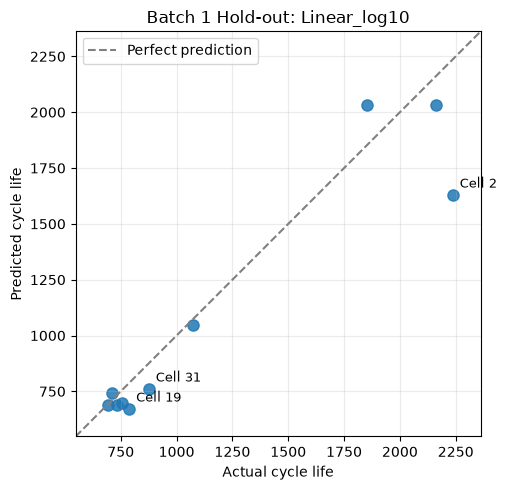

저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254/holdout_20261002_135537_771160


In [20]:
# 평가 전에 모델과 피처를 명시한다.
selected_model_name = "Linear_log10"
selected_features = ["delta_q_log_var"]

# 기존 분할과 데이터 유효성 확인
assert len(df_train) == 31
assert len(df_valid) == 10

for frame, split_name in [(df_train, "train"), (df_valid, "valid")]:
    expected = split_manifest.loc[
        split_manifest["split"].eq(split_name),
        ["batch", "cell_id"],
    ].reset_index(drop=True)

    pd.testing.assert_frame_equal(
        frame[["batch", "cell_id"]].reset_index(drop=True),
        expected,
    )
    assert frame["batch"].eq("Batch 1").all()
    assert np.isfinite(
        frame[selected_features + [target_col]].to_numpy(dtype=float)
    ).all()
    assert frame[target_col].gt(0).all()

assert set(df_train["protocol"]).isdisjoint(df_valid["protocol"])
assert set(df_train["barcode"]).isdisjoint(df_valid["barcode"])

# 선택 근거와 실행 설정을 평가 전에 기록
started_at = pd.Timestamp.now(tz="Asia/Seoul")
started_timer = perf_counter()

HOLDOUT_DIR = (
    RUN_DIR / f"holdout_{started_at.strftime('%Y%m%d_%H%M%S_%f')}"
)
HOLDOUT_DIR.mkdir(parents=True, exist_ok=False)

holdout_config = {
    "status": "running",
    "started_at": started_at.isoformat(),
    "model": selected_model_name,
    "features": selected_features,
    "target": target_col,
    "target_transform": "log10; predictions returned in cycles",
    "selection_basis": "既存のグループCV結果とモデルの単純性",
    "snapshot_dir": str(SNAPSHOT_DIR),
    "split_dir": str(RUN_DIR),
    "split_manifest_sha256": sha256(
        (RUN_DIR / "split_manifest.csv").read_bytes()
    ).hexdigest(),
    "n_train": len(df_train),
    "n_holdout": len(df_valid),
    "original_split_seed": int(SEED),
    "holdout_evaluated": False,
    "batch2_test_evaluated": False,
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "matplotlib_version": matplotlib.__version__,
}
holdout_config["selection_basis"] = (
    "기존 그룹 CV의 MAPE·RMSE와 모델의 단순성"
)

config_path = HOLDOUT_DIR / "holdout_config.json"
config_path.write_text(
    json.dumps(holdout_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 기존 기준 모델과 같은 정의를 복제하고 학습 31셀에만 fit
holdout_model = clone(baseline_models[selected_model_name])
holdout_model.fit(
    df_train[selected_features],
    df_train[target_col],
)

# TTR의 predict는 원래 사이클 단위의 값을 반환한다.
y_valid = df_valid[target_col].to_numpy(dtype=float)
pred_valid = holdout_model.predict(df_valid[selected_features])

assert np.isfinite(pred_valid).all()
assert (pred_valid > 0).all()

holdout_mape = mean_absolute_percentage_error(
    y_valid, pred_valid
) * 100
holdout_rmse = np.sqrt(mean_squared_error(y_valid, pred_valid))

# 셀별 예측과 오차
df_holdout_predictions = df_valid[
    ["batch", "cell_id", "protocol"]
].reset_index(drop=True).copy()

df_holdout_predictions["y_true"] = y_valid
df_holdout_predictions["y_pred"] = pred_valid
df_holdout_predictions["error_cycles"] = pred_valid - y_valid
df_holdout_predictions["APE_pct"] = (
    np.abs(pred_valid - y_valid) / y_valid * 100
)

# 기존 CV 평균과 hold-out 비교
cv_result = (
    df_baseline_summary.set_index("model").loc[selected_model_name]
)

df_holdout_comparison = pd.DataFrame([
    {
        "evaluation": "Batch 1 CV: 5-fold mean",
        "n_cells": len(df_train),
        "MAPE_pct": cv_result["MAPE_mean_pct"],
        "RMSE_cycles": cv_result["RMSE_mean_cycles"],
    },
    {
        "evaluation": "Batch 1 hold-out",
        "n_cells": len(df_valid),
        "MAPE_pct": holdout_mape,
        "RMSE_cycles": holdout_rmse,
    },
])

mape_gap_pp = holdout_mape - cv_result["MAPE_mean_pct"]

print("선택 후보:", selected_model_name)
display(df_holdout_comparison.round(3))
print(f"MAPE 차이 (hold-out − CV): {mape_gap_pp:+.3f}%p")

print("\n셀별 오차: APE가 큰 순서")
display(
    df_holdout_predictions
    .sort_values("APE_pct", ascending=False)
    .round(3)
)

# 실제값과 예측값 비교
fig, ax = plt.subplots(figsize=(6, 5))
ax.scatter(y_valid, pred_valid, s=65, alpha=0.85)

lower = float(min(y_valid.min(), pred_valid.min()))
upper = float(max(y_valid.max(), pred_valid.max()))
padding = max((upper - lower) * 0.08, 1.0)
limits = [lower - padding, upper + padding]

ax.plot(limits, limits, "--", color="gray", label="Perfect prediction")
ax.set_xlim(limits)
ax.set_ylim(limits)
ax.set_aspect("equal", adjustable="box")

# 오차가 큰 3개 셀 표시
for row in df_holdout_predictions.nlargest(3, "APE_pct").itertuples():
    ax.annotate(
        f"Cell {row.cell_id}",
        (row.y_true, row.y_pred),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=9,
    )

ax.set_xlabel("Actual cycle life")
ax.set_ylabel("Predicted cycle life")
ax.set_title("Batch 1 Hold-out: Linear_log10")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()

figure_path = HOLDOUT_DIR / "holdout_actual_vs_predicted.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

# 결과와 로그 타깃 공간의 회귀 계수 저장
df_holdout_comparison.to_csv(
    HOLDOUT_DIR / "holdout_metrics.csv",
    index=False, encoding="utf-8-sig",
)
df_holdout_predictions.to_csv(
    HOLDOUT_DIR / "holdout_predictions.csv",
    index=False, encoding="utf-8-sig",
)

holdout_config.update({
    "status": "completed",
    "finished_at": pd.Timestamp.now(tz="Asia/Seoul").isoformat(),
    "elapsed_seconds": perf_counter() - started_timer,
    "holdout_evaluated": True,
    "MAPE_gap_holdout_minus_cv_pp": float(mape_gap_pp),
    "log10_target_coefficient": float(
        np.ravel(holdout_model.regressor_.coef_)[0]
    ),
    "log10_target_intercept": float(
        np.asarray(holdout_model.regressor_.intercept_).item()
    ),
    "output_sha256": {
        filename: sha256((HOLDOUT_DIR / filename).read_bytes()).hexdigest()
        for filename in [
            "holdout_metrics.csv",
            "holdout_predictions.csv",
            "holdout_actual_vs_predicted.png",
        ]
    },
})
config_path.write_text(
    json.dumps(holdout_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("저장 위치:", HOLDOUT_DIR)

### Hold-out 검증 결과 해석

Batch 1 hold-out 10셀에서 MAPE는 9.146%로,
CV 평균 10.178%보다 1.032%p 낮았다.
반면 RMSE는 CV 평균 117.864사이클에서
hold-out 212.015사이클로 증가했다.
따라서 상대오차와 절대오차 관점의 평가가 다르게 나타났다.

가장 큰 오차는 Cell 2에서 발생했다.
실제 수명은 2237사이클이지만 1631.156사이클로 예측하여
약 606사이클을 과소 예측했고, 상대오차는 27.083%였다.
출력된 수치로 계산하면 이 셀 하나가 hold-out 전체 제곱오차의
약 81.7%를 차지한다. 큰 절대오차에 민감한 RMSE가 높게 나온
주요 이유를 이 사례에서 확인할 수 있다.

같은 충전 프로토콜을 사용하는 Cell 0·1·2에서도
실제 수명의 순서를 예측값이 재현하지 못했다.
이는 단일 ΔQ 피처가 전체 평균 오차를 낮추더라도,
개별 셀의 수명 차이까지 충분히 설명하지 못하는 사례다.

이번 hold-out에서는 10셀 중 8셀을 과소 예측했고,
2셀을 과대 예측했다.
운영 활용을 고려한다면 평균 오차뿐 아니라
수명을 실제보다 길게 예측하는 사례도 별도로 살펴볼 필요가 있다.
다만 표본이 작으므로 이러한 예측 방향이 다른 배치에서도
유지된다고 단정할 수는 없다.

CV 값은 폴드별 지표의 평균이고 hold-out 값은 10셀 전체의 지표이며,
학습에 사용한 셀 수도 서로 다르다.
따라서 지표 차이만으로 과적합 여부를 확정하지 않는다.
Cell 2 역시 예측 오차가 크다는 이유만으로 제외하지 않고,
현재 모델의 한계로 기록한다.

### Batch 2 최종 평가

Batch 1 내부 검증에서 선택한 모델과 피처를 유지하여
Batch 1 전체 41셀로 최종 모델을 재학습한다.

- 입력 피처: delta_q_log_var
- 모델: log10(Cycle Life)를 예측하는 선형회귀
- 최종 학습 데이터: Batch 1의 모델링 대상 41셀
- 최종 평가 데이터: Batch 2의 모델링 대상 39셀

재학습 과정에서 회귀계수는 달라지지만 모델 종류와 피처는 변경하지 않는다.
기존 CV와 hold-out 결과는 이전 학습 조건에서 얻은 점수로 보존한다.
재학습에 포함된 hold-out 셀을 다시 예측하여 검증 점수를 대체하지 않는다.

Batch 2의 예측값을 한 번 생성한 뒤 성능표와 오차 분석에 함께 사용한다.
최종 평가 결과를 근거로 모델을 다시 선택하거나,
오차가 큰 셀을 제외하여 점수를 개선하지 않는다.

MAPE 차이는 다음과 같이 정의한다.

- Valid − CV: 내부 검증의 상대오차 차이
- Test − Valid: 최종 평가와 내부 검증의 상대오차 차이
- Test − 9.1%: 과제에서 제시한 논문 참고 수치와의 차이

차이가 양수이면 비교 기준보다 오차가 크다는 의미다.
학습 표본 수와 평가 대상이 다르므로 Test − Valid를
순수한 배치 차이의 효과로 단정하지 않는다.

논문과 데이터 구성·전처리·분할·피처가 다르므로
9.1%와의 비교는 동일 조건의 재현 실험으로 해석하지 않는다.
또한 DAY1에서 Batch 2의 EDA를 수행했으므로,
사전 탐색까지 완전히 차단한 평가라는 주장도 하지 않는다.

In [22]:
FINAL_MODEL_NAME = "Linear_log10"
FINAL_FEATURES = ["delta_q_log_var"]
REFERENCE_MAPE_PCT = 9.1

# hold-out 평가 때 사용한 설정과 같은지 확인
assert selected_model_name == FINAL_MODEL_NAME
assert selected_features == FINAL_FEATURES
assert holdout_config["model"] == FINAL_MODEL_NAME
assert holdout_config["features"] == FINAL_FEATURES

assert len(df_dev) == 41
assert len(df_test) == 39
assert df_dev["batch"].eq("Batch 1").all()
assert df_test["batch"].eq("Batch 2").all()

# 최종 학습 데이터가 기존 train + hold-out과 일치하는지 확인
keys = ["batch", "cell_id"]
check_cols = keys + ["barcode"] + FINAL_FEATURES + [target_col]

previous_batch1 = pd.concat(
    [df_train, df_valid], ignore_index=True
)

pd.testing.assert_frame_equal(
    df_dev[check_cols].sort_values(keys).reset_index(drop=True),
    previous_batch1[check_cols].sort_values(keys).reset_index(drop=True),
)

# test 구성과 물리 셀 분리 확인
expected_test = split_manifest.loc[
    split_manifest["split"].eq("test"), keys + ["barcode"]
]
pd.testing.assert_frame_equal(
    df_test[keys + ["barcode"]].sort_values(keys).reset_index(drop=True),
    expected_test.sort_values(keys).reset_index(drop=True),
)

assert not df_dev["barcode"].duplicated().any()
assert not df_test["barcode"].duplicated().any()
assert set(df_dev["barcode"]).isdisjoint(df_test["barcode"])

for frame in [df_dev, df_test]:
    assert np.isfinite(
        frame[FINAL_FEATURES + [target_col]].to_numpy(dtype=float)
    ).all()
    assert frame[target_col].gt(0).all()

# 평가 전에 고정 설정과 출처를 저장
started_at = pd.Timestamp.now(tz="Asia/Seoul")
started_timer = perf_counter()

FINAL_DIR = (
    RUN_DIR / f"final_test_{started_at.strftime('%Y%m%d_%H%M%S_%f')}"
)
FINAL_DIR.mkdir(parents=True, exist_ok=False)

final_config = {
    "status": "running",
    "started_at": started_at.isoformat(),
    "model": FINAL_MODEL_NAME,
    "features": FINAL_FEATURES,
    "target": target_col,
    "target_transform": "log10",
    "inverse_transform": "10**z",
    "n_final_train": len(df_dev),
    "n_test": len(df_test),
    "snapshot_dir": str(SNAPSHOT_DIR),
    "snapshot_csv_sha256": sha256(
        (SNAPSHOT_DIR / "model_candidates.csv").read_bytes()
    ).hexdigest(),
    "split_dir": str(RUN_DIR),
    "split_manifest_sha256": sha256(
        (RUN_DIR / "split_manifest.csv").read_bytes()
    ).hexdigest(),
    "holdout_result_dir": str(HOLDOUT_DIR),
    "original_split_seed": int(SEED),
    "reference_MAPE_pct": REFERENCE_MAPE_PCT,
    "reference_note": "과제의 논문 참고 수치; 동일 조건의 재현 비교 아님",
    "prior_batch2_EDA": True,
    "batch2_evaluated": False,
    "python_version": sys.version,
    "numpy_version": np.__version__,
    "pandas_version": pd.__version__,
    "sklearn_version": sklearn.__version__,
    "joblib_version": joblib.__version__,
    "matplotlib_version": matplotlib.__version__,
}

config_path = FINAL_DIR / "final_config.json"
config_path.write_text(
    json.dumps(final_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

# 모델 종류와 피처를 유지하고 Batch 1 전체 41셀에 재학습
final_model = clone(baseline_models[FINAL_MODEL_NAME])
final_model.fit(df_dev[FINAL_FEATURES], df_dev[target_col])

# 내부 회귀기와 변환 정보를 함께 저장
# 저장된 회귀기의 predict 출력은 log10 수명이다.
model_bundle = {
    "regressor": final_model.regressor_,
    "features": FINAL_FEATURES,
    "target": target_col,
    "target_transform": "log10",
    "inverse_transform": "10**z",
    "sklearn_version": sklearn.__version__,
}
model_path = FINAL_DIR / "final_model_bundle.joblib"
joblib.dump(model_bundle, model_path)

# 저장·복원 확인은 Batch 1의 일부 입력으로 수행
restored_bundle = joblib.load(model_path)
check_X = df_dev[FINAL_FEATURES].iloc[:3]

restored_predictions = np.power(
    10.0,
    restored_bundle["regressor"].predict(check_X),
)
np.testing.assert_allclose(
    restored_predictions,
    final_model.predict(check_X),
    rtol=1e-12,
    atol=1e-10,
)

# Batch 2 최종 예측: 이후 표와 그림에서 이 배열을 재사용
y_test = df_test[target_col].to_numpy(dtype=float)
pred_test = final_model.predict(df_test[FINAL_FEATURES])

assert np.isfinite(pred_test).all()
assert (pred_test > 0).all()

test_mape = mean_absolute_percentage_error(y_test, pred_test) * 100
test_rmse = np.sqrt(mean_squared_error(y_test, pred_test))

# 기존 CV·hold-out 결과에 Test 결과만 추가
df_final_metrics = pd.concat([
    df_holdout_comparison.copy(),
    pd.DataFrame([{
        "evaluation": "Batch 2 final test",
        "n_cells": len(df_test),
        "MAPE_pct": test_mape,
        "RMSE_cycles": test_rmse,
    }]),
], ignore_index=True)

df_final_metrics["note"] = [
    "폴드 평균; 각 모델 학습 24~25셀",
    "학습 31셀",
    "최종 재학습 41셀",
]

cv_mape = float(df_final_metrics.iloc[0]["MAPE_pct"])
valid_mape = float(df_final_metrics.iloc[1]["MAPE_pct"])

df_final_gaps = pd.DataFrame([
    {"comparison": "Valid - CV",
     "MAPE_gap_pp": valid_mape - cv_mape},
    {"comparison": "Test - Valid",
     "MAPE_gap_pp": test_mape - valid_mape},
    {"comparison": "Test - reference 9.1%",
     "MAPE_gap_pp": test_mape - REFERENCE_MAPE_PCT},
])

# 셀별 예측 결과
df_test_predictions = df_test[
    ["batch", "cell_id", "protocol"]
].reset_index(drop=True).copy()

df_test_predictions["y_true"] = y_test
df_test_predictions["y_pred"] = pred_test
df_test_predictions["error_cycles"] = pred_test - y_test
df_test_predictions["APE_pct"] = (
    np.abs(pred_test - y_test) / y_test * 100
)

# 결과 저장
final_tables = {
    "final_metrics.csv": df_final_metrics,
    "final_gaps.csv": df_final_gaps,
    "test_predictions.csv": df_test_predictions,
}
for filename, table in final_tables.items():
    table.to_csv(
        FINAL_DIR / filename, index=False, encoding="utf-8-sig"
    )

final_config.update({
    "status": "evaluation_completed",
    "finished_at": pd.Timestamp.now(tz="Asia/Seoul").isoformat(),
    "elapsed_seconds": perf_counter() - started_timer,
    "batch2_evaluated": True,
    "log10_target_coefficient": float(
        np.ravel(final_model.regressor_.coef_)[0]
    ),
    "log10_target_intercept": float(
        np.asarray(final_model.regressor_.intercept_).item()
    ),
    "output_sha256": {
        filename: sha256((FINAL_DIR / filename).read_bytes()).hexdigest()
        for filename in list(final_tables) + ["final_model_bundle.joblib"]
    },
})
config_path.write_text(
    json.dumps(final_config, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("CV · Hold-out · 최종 Test 성능")
display(df_final_metrics.round(3))

print("MAPE 차이: 양수이면 비교 기준보다 오차가 큼")
display(df_final_gaps.round(3))

print("최종 모델 저장·복원 예측 일치 확인 완료")
print("저장 위치:", FINAL_DIR)

CV · Hold-out · 최종 Test 성능


,evaluation,n_cells,MAPE_pct,RMSE_cycles,note
0,Batch 1 CV: 5-fold mean,31,10.178,117.864,폴드 평균; 각 모델 학습 24~25셀
1,Batch 1 hold-out,10,9.146,212.015,학습 31셀
2,Batch 2 final test,39,26.175,170.525,최종 재학습 41셀


MAPE 차이: 양수이면 비교 기준보다 오차가 큼


,comparison,MAPE_gap_pp
0,Valid - CV,-1.032
1,Test - Valid,17.029
2,Test - reference 9.1%,17.075


최종 모델 저장·복원 예측 일치 확인 완료
저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254/final_test_20261002_140941_363275


### 최종 평가 결과 해석

최종 모델은 Batch 2의 39셀에서 MAPE 26.175%,
RMSE 170.525사이클을 기록했다.
Batch 1 hold-out의 MAPE 9.146%보다 17.029%p 높아,
내부 검증에서 확인한 상대오차 수준이 다른 배치에서는 유지되지 않았다.

RMSE는 hold-out의 212.015사이클보다 낮아졌지만,
CV 평균 117.864사이클보다는 높았다.
MAPE는 실제 수명에 대한 상대오차이고 RMSE는 사이클 단위의 오차이므로,
두 지표의 변화 방향이 항상 일치하지는 않는다.
예를 들어 같은 100사이클 오차도 실제 수명이 500사이클이면 20%,
2000사이클이면 5%의 상대오차가 된다.

앞선 hold-out에서는 Cell 2의 큰 절대오차가 RMSE에 영향을 주었다.
Batch 2의 오차 구간과 예측 방향은 아래의 저장 예측값 분석에서 확인한다.
그 결과 39셀 중 38셀을 과대 예측했고, 단수명·중간 수명 구간의 모든 셀에서
과대 예측이 나타났다. 이는 평균 오차 증가와 함께 예측 방향의 편향도
살펴봐야 한다는 근거이며, 특정 충전 조건이나 배치 차이를 원인으로
확정하는 증거는 아니다.

과제에서 제시한 논문 참고 성능 9.1%보다
최종 MAPE가 17.075%p 높아 해당 참고 수준에는 도달하지 못했다.
다만 데이터 구성, 전처리, 분할 및 피처가 다르므로
동일 조건에서 논문 모델과 성능을 비교한 결과로 해석하지 않는다.

이번 결과를 통해 내부 검증에서 가장 좋은 모델을 선택하더라도,
다른 배치에서의 성능 확인이 별도로 필요함을 확인했다.
EDA에서 관찰한 피처와 수명의 연관성에 더해,
학습한 관계가 다른 데이터에서도 정확한 수명 예측으로 이어지는지
검증해야 한다는 점이 핵심 시사점이다.

최종 결과는 그대로 보존하고, 저장된 예측값을 이용해
오차가 큰 셀과 수명 구간을 분석한다.
평가 표본과 학습 규모도 달라졌으므로 성능 차이의 원인을
과적합이나 배치 차이 하나로 단정하지 않는다.

### 최종 예측의 수명 구간별 오차 분석

Batch 2의 최종 MAPE는 26.175%였다.
전체 평균만으로는 오차가 발생한 구간과 예측 방향을 알기 어려우므로,
저장된 셀별 예측값을 이용해 다음 내용을 확인한다.

- 실제 수명 구간별 셀 수와 MAPE·RMSE
- 수명을 과대 또는 과소 예측하는 경향
- 상대오차가 큰 개별 셀

수명 구간은 DAY1 기준을 유지한다.

- Short: 실제 수명 500사이클 미만
- Middle: 실제 수명 500~1000사이클
- Long: 실제 수명 1000사이클 초과

이 구분은 평가 후 오차를 설명하기 위한 것이며 모델 입력으로 사용하지 않는다.
잔차는 예측 수명 − 실제 수명으로 정의한다.
양수이면 과대 예측, 음수이면 과소 예측이다.

평균 잔차는 양수와 음수가 상쇄될 수 있으므로 MAPE·RMSE와 함께 해석한다.
표본이 적은 구간의 결과는 일반화하지 않으며,
이 분석을 근거로 최종 Test에 맞춰 모델을 다시 선택하거나 셀을 제외하지 않는다.

실제 수명 구간별 오차


,n_cells,MAPE_pct,RMSE_cycles,mean_error_cycles,overprediction_pct
life_group,,,,,
Short,28,26.496,135.011,117.382,100.000
Middle,8,31.508,270.289,235.119,100.000
Long,3,8.952,114.367,85.785,66.667


상대오차가 큰 상위 10셀


,cell_id,protocol,life_group,y_true,y_pred,error_cycles,APE_pct
18,18,5.2C(50%)-4.25C,Short,449.0,730.479,281.479,62.690
6,6,3.6C(9%)-5C,Short,393.0,632.282,239.282,60.886
15,15,3.6C(9%)-5C,Short,396.0,625.222,229.222,57.884
9,9,5.6C(26%)-4.5C-newstructure,Middle,791.0,1227.308,436.308,55.159
36,44,5.2C(58%)-4C-newstructure,Middle,841.0,1247.562,406.562,48.343
7,7,4.8C(80%)-4.8C-newstructure,Middle,777.0,1119.625,342.625,44.096
2,2,5.2C(50%)-4.25C,Short,424.0,597.346,173.346,40.884
27,29,5.2C(58%)-4C,Short,452.0,621.160,169.160,37.425
11,11,5.2C(50%)-4.25C,Short,449.0,609.705,160.705,35.792
22,24,4.8C(80%)-4.8C,Middle,514.0,692.016,178.016,34.633


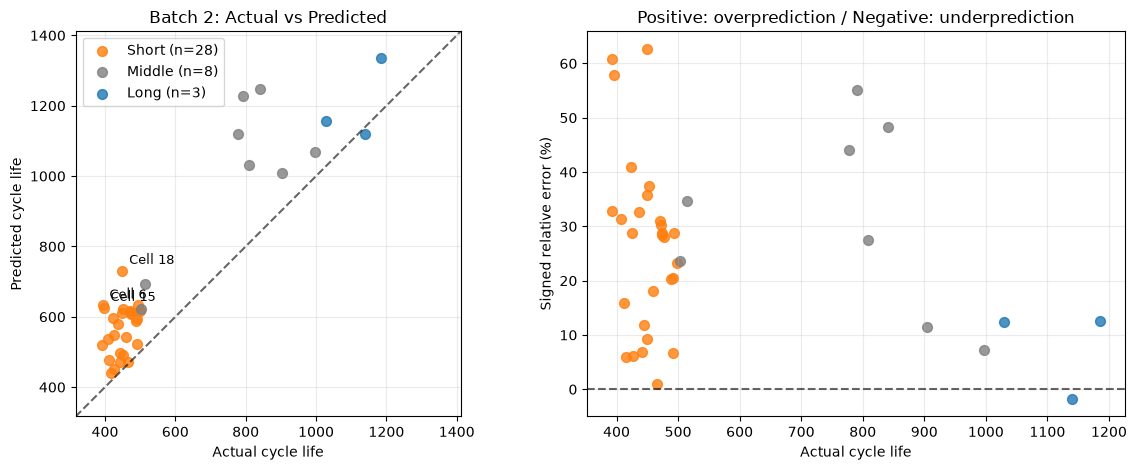

오차 분석 저장 위치: /Users/kim-youngjun/ess-battery-project/outputs/modeling/group_split_20261002_132656_557254/final_test_20261002_140941_363275/error_analysis_20261002_143735_159129


In [23]:
# 최종 평가 때 저장한 예측값만 읽는다.
prediction_path = FINAL_DIR / "test_predictions.csv"
saved_final_config = json.loads(
    (FINAL_DIR / "final_config.json").read_text(encoding="utf-8")
)
prediction_sha = sha256(prediction_path.read_bytes()).hexdigest()

assert prediction_sha == saved_final_config["output_sha256"][
    "test_predictions.csv"
], "저장된 예측 파일이 변경되었습니다."

df_error = pd.read_csv(prediction_path)

assert len(df_error) == 39
assert df_error["batch"].eq("Batch 2").all()
assert not df_error.duplicated(["batch", "cell_id"]).any()
assert np.isfinite(
    df_error[["y_true", "y_pred"]].to_numpy(dtype=float)
).all()
assert df_error[["y_true", "y_pred"]].gt(0).all().all()

# 같은 예측값에서 오차 지표를 계산
df_error["error_cycles"] = df_error["y_pred"] - df_error["y_true"]
df_error["signed_error_pct"] = (
    df_error["error_cycles"] / df_error["y_true"] * 100
)
df_error["APE_pct"] = df_error["signed_error_pct"].abs()
df_error["overpredicted"] = df_error["error_cycles"].gt(0)

# DAY1에서 사용한 경계 유지: 500과 1000은 Middle
df_error["life_group"] = np.select(
    [
        df_error["y_true"].lt(500),
        df_error["y_true"].gt(1000),
    ],
    ["Short", "Long"],
    default="Middle",
)

# 수명 구간별 오차 요약
df_error_by_life = (
    df_error.groupby("life_group")
    .agg(
        n_cells=("cell_id", "size"),
        MAPE_pct=("APE_pct", "mean"),
        RMSE_cycles=(
            "error_cycles",
            lambda values: np.sqrt(np.mean(np.square(values))),
        ),
        mean_error_cycles=("error_cycles", "mean"),
        overprediction_pct=(
            "overpredicted",
            lambda values: values.mean() * 100,
        ),
    )
    .reindex(["Short", "Middle", "Long"])
)
df_error_by_life["n_cells"] = (
    df_error_by_life["n_cells"].fillna(0).astype(int)
)

print("실제 수명 구간별 오차")
display(df_error_by_life.round(3))

print("상대오차가 큰 상위 10셀")
display(
    df_error.sort_values("APE_pct", ascending=False)[[
        "cell_id", "protocol", "life_group",
        "y_true", "y_pred", "error_cycles", "APE_pct",
    ]].head(10).round(3)
)

# 실제값-예측값 및 수명 구간별 오차 방향
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
colors = {
    "Short": "tab:orange",
    "Middle": "tab:gray",
    "Long": "tab:blue",
}

for group_name, color in colors.items():
    part = df_error.loc[df_error["life_group"].eq(group_name)]
    if part.empty:
        continue

    axes[0].scatter(
        part["y_true"], part["y_pred"],
        color=color, label=f"{group_name} (n={len(part)})",
        s=50, alpha=0.8,
    )
    axes[1].scatter(
        part["y_true"], part["signed_error_pct"],
        color=color, label=group_name,
        s=50, alpha=0.8,
    )

values = df_error[["y_true", "y_pred"]].to_numpy()
lower, upper = float(values.min()), float(values.max())
padding = max((upper - lower) * 0.08, 1.0)
limits = [lower - padding, upper + padding]

axes[0].plot(limits, limits, "--", color="black", alpha=0.6)
axes[0].set_xlim(limits)
axes[0].set_ylim(limits)
axes[0].set_aspect("equal", adjustable="box")
axes[0].set_xlabel("Actual cycle life")
axes[0].set_ylabel("Predicted cycle life")
axes[0].set_title("Batch 2: Actual vs Predicted")
axes[0].legend()

for row in df_error.nlargest(3, "APE_pct").itertuples():
    axes[0].annotate(
        f"Cell {row.cell_id}",
        (row.y_true, row.y_pred),
        xytext=(5, 5), textcoords="offset points", fontsize=9,
    )

axes[1].axhline(0, linestyle="--", color="black", alpha=0.6)
axes[1].set_xlabel("Actual cycle life")
axes[1].set_ylabel("Signed relative error (%)")
axes[1].set_title("Positive: overprediction / Negative: underprediction")

for ax in axes:
    ax.grid(alpha=0.25)

fig.tight_layout()

# 최종 평가 파일을 보존하고 진단 결과를 별도 저장
diagnostic_time = pd.Timestamp.now(tz="Asia/Seoul")
DIAGNOSTIC_DIR = (
    FINAL_DIR
    / f"error_analysis_{diagnostic_time.strftime('%Y%m%d_%H%M%S_%f')}"
)
DIAGNOSTIC_DIR.mkdir(parents=True, exist_ok=False)

df_error_by_life.reset_index().to_csv(
    DIAGNOSTIC_DIR / "errors_by_life_group.csv",
    index=False, encoding="utf-8-sig",
)
df_error.to_csv(
    DIAGNOSTIC_DIR / "cell_errors.csv",
    index=False, encoding="utf-8-sig",
)
fig.savefig(
    DIAGNOSTIC_DIR / "test_error_analysis.png",
    dpi=180, bbox_inches="tight",
)
plt.show()
plt.close(fig)

diagnostic_metadata = {
    "created_at": diagnostic_time.isoformat(),
    "source_predictions": str(prediction_path),
    "source_predictions_sha256": prediction_sha,
    "final_config": str(FINAL_DIR / "final_config.json"),
    "group_definitions": {
        "Short": "y_true < 500",
        "Middle": "500 <= y_true <= 1000",
        "Long": "y_true > 1000",
    },
    "model_refitted": False,
    "new_predictions_generated": False,
}
(DIAGNOSTIC_DIR / "diagnostic_metadata.json").write_text(
    json.dumps(diagnostic_metadata, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print("오차 분석 저장 위치:", DIAGNOSTIC_DIR)

### 오차 분석 결과와 도메인 시사점

Batch 2의 39셀 중 38셀(97.4%)에서 예측 수명이 실제 수명보다 길었다.
전체 MAPE 26.175%만 보면 드러나지 않는, 수명 과대 예측의 방향성을 확인했다.

실제 수명 500사이클 미만의 Short 구간은 28셀 모두 과대 예측했으며
MAPE는 26.496%, 평균 잔차는 +117.382사이클이었다.
500~1000사이클의 Middle 구간도 8셀 모두 과대 예측했고,
MAPE는 31.508%, 평균 잔차는 +235.119사이클이었다.
따라서 단수명 구간에서만 오차가 발생한 것이 아니며,
이번 평가에서는 중간 수명 구간의 평균 상대오차가 더 컸다.
1000사이클을 초과하는 Long 구간의 MAPE는 8.952%였지만
표본이 3셀뿐이므로 장수명 배터리 전반에 대한 예측력이 좋다고 일반화하지 않는다.

이 결과에서 내가 주목한 점은 평균 성능뿐 아니라 오차의 방향이다.
초기 사이클의 신호로 총 수명을 예측하는 모델을 교체 계획에 그대로 활용한다면,
수명 과대 예측은 실제보다 늦은 교체 시점을 계획하게 할 가능성이 있다.
따라서 평균 MAPE가 낮은 모델을 고르는 것과 함께,
실제 적용 대상에서 수명을 길게 예측하는 경향이 있는지도 확인해야 한다.
현재 결과는 실험 데이터의 총 수명 예측이며,
운영 환경의 교체 시점이나 안전성을 직접 검증한 결과는 아니다.

Batch 1 hold-out에서는 10셀 중 8셀을 과소 예측했지만,
Batch 2에서는 대부분의 셀을 과대 예측했다.
다만 최종 모델은 학습 규모가 31셀에서 41셀로 늘면서 회귀계수도 달라졌고,
평가 대상도 바뀌었다. 따라서 방향 변화의 원인을 배치 차이 하나로 단정하지 않는다.
학습 데이터의 대표성, 피처와 수명의 관계 변화, 개별 셀 차이는
향후 독립 자료에서 확인할 가설로 남긴다.

이번 비교에서는 ΔQ 로그분산 단일 피처 모델이 내부 CV에서 가장 낮은 오차를 보였고,
보조 피처 추가와 규제 회귀가 이를 개선하지 못했다.
이는 현재 후보와 탐색 범위에서 단순 모델을 선택할 근거이며,
모든 가능한 모델 중 최적이라는 의미는 아니다.
또한 내부 검증에서 선택한 모델도 Batch 2에서 같은 수준의 성능을 유지하지 못했다.
피처와 수명의 상관관계가 관찰된다는 사실만으로
새로운 배치의 수명을 정확히 예측할 수 있다고 판단할 수 없음을 배웠다.

최종 Test 결과와 평가 대상은 유지한다.
이 결과를 보고 다시 튜닝하거나 오차가 큰 셀을 제외하지 않는다.
추가 개선은 새 실험으로 구분하고, 새로운 독립 평가 자료를 확보한 뒤 검증해야 한다.
DAY1에서 Batch 2를 탐색했다는 한계도 남기며,
실제 운영 자료를 이용한 Live Test와 모니터링은 수행하지 않았다.

### 과제 양식에 따른 성능 요약

선택 모델은 `delta_q_log_var` 하나로 `log10(Cycle Life)`를 예측하는 선형회귀다.
아래 표는 이미 저장된 최종 성능 파일을 읽어 과제의 6행 양식으로 정리한다.
모델을 다시 학습하거나 Batch 2 예측을 새로 생성하지 않는다.

Train은 Batch 1의 학습 부분 31셀에서 얻은 그룹 5-fold 검증 성능의 평균이다.
훈련 데이터에 직접 적합해 계산한 오차가 아니므로,
Train과 Valid의 차이만으로 과적합 여부를 확정하지 않는다.

행 이름은 과제의 `Gap (Train-Valid)`, `Gap (Valid-Test)`, `Gap (Target-Test)`를 유지한다.
양수일 때 비교 기준보다 오차가 커졌다는 뜻이 되도록,
실제 계산식은 각각 **Valid − Train**, **Test − Valid**, **Test − Target**으로 정의한다.
앞의 세 행은 MAPE의 **%**, Gap 세 행은 차이의 **%p**이며 비고에 구분해서 적는다.
Target은 과제에서 제시한 9.1%이고, 데이터·전처리·분할·피처가 달라
동일 조건의 논문 재현 성능으로 해석하지 않는다.

정리한 표는 `results/model_performance.csv`에도 저장한다.


In [1]:
# 기존 최종 평가 파일에서 성능표만 구성한다. 추가 fit/predict는 수행하지 않는다.
report_config = json.loads(
    (FINAL_DIR / "final_config.json").read_text(encoding="utf-8")
)
report_metrics_path = FINAL_DIR / "final_metrics.csv"
assert sha256(report_metrics_path.read_bytes()).hexdigest() == (
    report_config["output_sha256"]["final_metrics.csv"]
), "저장된 최종 성능 파일이 변경되었습니다."

report_metrics = pd.read_csv(report_metrics_path).set_index("evaluation")
assert report_metrics.index.is_unique
assert set(report_metrics.index) == {
    "Batch 1 CV: 5-fold mean", "Batch 1 hold-out", "Batch 2 final test"
}

report_train = float(report_metrics.loc["Batch 1 CV: 5-fold mean", "MAPE_pct"])
report_valid = float(report_metrics.loc["Batch 1 hold-out", "MAPE_pct"])
report_test = float(report_metrics.loc["Batch 2 final test", "MAPE_pct"])
report_target = float(report_config["reference_MAPE_pct"])
assert np.isfinite([report_train, report_valid, report_test, report_target]).all()

# 반올림 전 값으로 차이를 계산하고, 출력할 때만 소수 셋째 자리로 표시한다.
df_performance_report = pd.DataFrame([
    ["Train (Batch 1 CV)", report_train,
     "단위 %; 31셀의 그룹 5-fold 평균, 각 폴드 학습 24~25셀"],
    ["Valid (Batch 1 Hold-out)", report_valid,
     "단위 %; 학습 31셀 → 프로토콜이 분리된 검증 10셀"],
    ["Test (Batch 2)", report_test,
     "단위 %; Batch 1 전체 41셀 재학습 → Batch 2의 39셀 평가"],
    ["Gap (Train-Valid)", report_valid - report_train,
     "단위 %p; Valid − Train; (+) 검증 오차 증가, 과적합 여부는 추가 판단"],
    ["Gap (Valid-Test)", report_test - report_valid,
     "단위 %p; Test − Valid; (+) 배치 간 일반화 성능 저하 의심"],
    ["Gap (Target-Test)", report_test - report_target,
     f"단위 %p; Test − Target; Target = 논문 참고 {report_target:.1f}%"],
], columns=["구분", "MAPE (%)", "비고"])

# 제출용 요약을 프로젝트의 results 폴더에 저장한다.
# FINAL_DIR = 프로젝트/outputs/modeling/분할실험/최종평가
RESULTS_DIR = FINAL_DIR.parents[3] / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
df_performance_report.to_csv(
    RESULTS_DIR / "model_performance.csv", index=False, encoding="utf-8-sig"
)

print("회귀 모델 성능 — 과제 지정 양식")
report_display = df_performance_report.copy()
report_display["MAPE (%)"] = [
    f"{value:+.3f}" if row >= 3 else f"{value:.3f}"
    for row, value in enumerate(df_performance_report["MAPE (%)"])
]
display(
    {"text/html": report_display.to_html(index=False),
     "text/plain": report_display.to_string(index=False)},
    raw=True,
)

회귀 모델 성능 — 과제 지정 양식


구분,MAPE (%),비고
Train (Batch 1 CV),10.178,"단위 %; 31셀의 그룹 5-fold 평균, 각 폴드 학습 24~25셀"
Valid (Batch 1 Hold-out),9.146,단위 %; 학습 31셀 → 프로토콜이 분리된 검증 10셀
Test (Batch 2),26.175,단위 %; Batch 1 전체 41셀 재학습 → Batch 2의 39셀 평가
Gap (Train-Valid),-1.032,"단위 %p; Valid − Train; (+) 검증 오차 증가, 과적합 여부는 추가 판단"
Gap (Valid-Test),+17.029,단위 %p; Test − Valid; (+) 배치 간 일반화 성능 저하 의심
Gap (Target-Test),+17.075,단위 %p; Test − Target; Target = 논문 참고 9.1%
